In [1]:
# ============================================================
# 04 · Cell 1 — Setup, data load and factor definitions
# ============================================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from commodity_factors.config import PATHS, UNIVERSE, Sector

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

BACKTEST_START = "2002-01-31"

# Factor definitions (decided in notebook 03)
PRIMARY_CROSS_SECTIONAL = ["mom_12_1", "carry", "value", "skewness", "hedging_pressure"]
PRIMARY_TIME_SERIES = ["tsmom_12"]
ROBUSTNESS_CROSS_SECTIONAL = ["mom_12_0", "hp_demeaned", "hp_speculator"]
ROBUSTNESS_ENERGY_TIME_SERIES = ["carry_eia_adj", "carry_eia_raw", "basis_momentum"]

# Data
daily_returns = pd.read_parquet(PATHS.processed / "returns_daily.parquet")
monthly_returns = pd.read_parquet(PATHS.processed / "returns_monthly.parquet")
benchmarks = pd.read_parquet(PATHS.processed / "benchmarks_monthly.parquet")
signal_panel = pd.read_parquet(PATHS.processed / "signals.parquet")

# Last complete month (same rule as notebook 03)
last_day = daily_returns.index[-1]
is_month_close = last_day == last_day + pd.offsets.BMonthEnd(0)
LAST_COMPLETE_MONTH = (
    last_day + pd.offsets.MonthEnd(0) if is_month_close else last_day - pd.offsets.MonthEnd(1)
)
monthly_returns = monthly_returns.loc[:LAST_COMPLETE_MONTH]
benchmarks = benchmarks.loc[:LAST_COMPLETE_MONTH]

signals = {
    name: signal_panel[name].dropna(how="all", axis=1)
    for name in signal_panel.columns.get_level_values("signal").unique()
}

# Check every defined factor exists
defined = (PRIMARY_CROSS_SECTIONAL + PRIMARY_TIME_SERIES
           + ROBUSTNESS_CROSS_SECTIONAL + ROBUSTNESS_ENERGY_TIME_SERIES)
missing = sorted(set(defined) - set(signals))
assert not missing, f"Signals missing from signals.parquet: {missing}"

print(f"Last complete month : {LAST_COMPLETE_MONTH:%Y-%m-%d}")
print(f"Monthly returns     : {monthly_returns.shape[0]} months x {monthly_returns.shape[1]} contracts")
print(f"Backtest start      : {BACKTEST_START}\n")

for group, names in [
    ("Primary cross-sectional", PRIMARY_CROSS_SECTIONAL),
    ("Primary time-series", PRIMARY_TIME_SERIES),
    ("Robustness cross-sectional", ROBUSTNESS_CROSS_SECTIONAL),
    ("Robustness energy time-series", ROBUSTNESS_ENERGY_TIME_SERIES),
]:
    print(group)
    for name in names:
        valid = signals[name].dropna(how="all")
        print(f"  {name:<17}: {valid.index.min():%Y-%m} -> {valid.index.max():%Y-%m}, "
              f"{signals[name].shape[1]} contracts")
    print()

Last complete month : 2026-09-30
Monthly returns     : 321 months x 26 contracts
Backtest start      : 2002-01-31

Primary cross-sectional
  mom_12_1         : 2001-01 -> 2026-09, 26 contracts
  carry            : 2000-12 -> 2026-09, 26 contracts
  value            : 2005-04 -> 2026-09, 26 contracts
  skewness         : 2000-10 -> 2026-09, 26 contracts
  hedging_pressure : 1987-09 -> 2026-09, 26 contracts

Primary time-series
  tsmom_12         : 2001-01 -> 2026-09, 26 contracts

Robustness cross-sectional
  mom_12_0         : 2001-01 -> 2026-09, 26 contracts
  hp_demeaned      : 1990-09 -> 2026-09, 26 contracts
  hp_speculator    : 1987-09 -> 2026-09, 26 contracts

Robustness energy time-series
  carry_eia_adj    : 1988-01 -> 2024-03, 4 contracts
  carry_eia_raw    : 1985-01 -> 2024-03, 4 contracts
  basis_momentum   : 2000-12 -> 2024-03, 4 contracts



In [2]:
%%writefile src/commodity_factors/risk.py
"""Ex-ante risk estimates for position sizing."""

from __future__ import annotations

import numpy as np
import pandas as pd


class EWMAVolatility:
    """Ex-ante annualised volatility from daily returns, sampled at month-end.

    Exponentially weighted variance with centre of mass ``com`` trading days
    (60 follows Moskowitz, Ooi & Pedersen, 2012). Missing days (e.g. masked
    roll days) are skipped. The value at month-end t uses data up to t only.
    """

    def __init__(
        self,
        daily_returns: pd.DataFrame,
        com: int = 60,
        min_periods: int = 60,
        trading_days: int = 252,
    ) -> None:
        self._daily_returns = daily_returns
        self._com = com
        self._min_periods = min_periods
        self._trading_days = trading_days

    def compute(self) -> pd.DataFrame:
        variance = self._daily_returns.ewm(
            com=self._com, min_periods=self._min_periods, ignore_na=True
        ).var()
        annualised = np.sqrt(variance * self._trading_days)
        return annualised.resample("ME").last()

Writing src/commodity_factors/risk.py


In [3]:
%%writefile src/commodity_factors/portfolio.py
"""Factor portfolio construction and monthly backtesting."""

from __future__ import annotations

from abc import ABC, abstractmethod
from dataclasses import dataclass

import numpy as np
import pandas as pd


class PortfolioConstructor(ABC):
    """Turns a signal panel (month-end x contract) into target weights."""

    @abstractmethod
    def weights(self, signal: pd.DataFrame) -> pd.DataFrame:
        """Target weights at each month-end, held over the following month."""


class QuantileLongShort(PortfolioConstructor):
    """Long the top quantile, short the bottom quantile of a cross-sectional signal.

    Each leg sums to 1 in absolute terms (dollar-neutral, gross exposure 2).
    Within a leg, weights are equal or inversely proportional to ex-ante volatility.
    With ``sectors``, contracts are ranked within their own sector first, so the
    portfolio does not take net sector bets driven by sector-wide signal levels.
    """

    def __init__(
        self,
        quantile: float = 1 / 3,
        volatility: pd.DataFrame | None = None,
        sectors: dict[str, str] | None = None,
        min_assets: int = 9,
    ) -> None:
        if not 0 < quantile <= 0.5:
            raise ValueError("quantile must be in (0, 0.5].")
        self._quantile = quantile
        self._volatility = volatility
        self._sectors = sectors
        self._min_assets = min_assets

    def weights(self, signal: pd.DataFrame) -> pd.DataFrame:
        score = self._sector_relative(signal) if self._sectors else signal
        pct = score.rank(axis=1, pct=True)
        enough = (score.notna().sum(axis=1) >= self._min_assets).to_numpy()[:, None]

        long = pct.gt(1 - self._quantile) & enough
        short = pct.le(self._quantile) & enough
        scale = self._scale(signal)
        return self._normalise(scale.where(long)) - self._normalise(scale.where(short))

    def _sector_relative(self, signal: pd.DataFrame) -> pd.DataFrame:
        groups = pd.Series(self._sectors).reindex(signal.columns)
        ranked = signal.T.groupby(groups).rank(pct=True).T
        return ranked.where(signal.notna())

    def _scale(self, signal: pd.DataFrame) -> pd.DataFrame:
        if self._volatility is None:
            return pd.DataFrame(1.0, index=signal.index, columns=signal.columns)
        vol = self._volatility.reindex(index=signal.index, columns=signal.columns)
        return 1.0 / vol.where(vol > 0)

    @staticmethod
    def _normalise(leg: pd.DataFrame) -> pd.DataFrame:
        return leg.div(leg.sum(axis=1), axis=0).fillna(0.0)


class VolScaledTimeSeries(PortfolioConstructor):
    """Long/short each contract on the sign of its own signal, scaled to target volatility.

    Weight = sign(signal) x (asset_target_vol / ex-ante vol) / N, where N is the number
    of contracts with a signal and a volatility estimate (Moskowitz, Ooi & Pedersen, 2012).
    """

    def __init__(self, volatility: pd.DataFrame, asset_target_vol: float = 0.40) -> None:
        self._volatility = volatility
        self._asset_target_vol = asset_target_vol

    def weights(self, signal: pd.DataFrame) -> pd.DataFrame:
        vol = self._volatility.reindex(index=signal.index, columns=signal.columns)
        raw = np.sign(signal) * self._asset_target_vol / vol.where(vol > 0)
        n_assets = raw.notna().sum(axis=1).replace(0, np.nan)
        return raw.div(n_assets, axis=0).fillna(0.0)


@dataclass(frozen=True)
class BacktestResult:
    """Monthly backtest output; returns are labelled by the month they are earned."""

    weights: pd.DataFrame
    gross: pd.Series
    net: pd.Series
    long_leg: pd.Series
    short_leg: pd.Series
    turnover: pd.Series

    def summary_frame(self) -> pd.DataFrame:
        return pd.DataFrame(
            {
                "gross": self.gross,
                "net": self.net,
                "long_leg": self.long_leg,
                "short_leg": self.short_leg,
                "turnover": self.turnover,
            }
        )


class Backtester:
    """Applies month-end weights to the following month's excess returns.

    Weights set at month-end t earn returns in month t+1. Transaction costs are
    charged on turnover (sum of absolute weight changes) at ``cost_per_turnover``.
    A held contract with a missing return contributes zero for that month.
    """

    def __init__(self, monthly_returns: pd.DataFrame, cost_per_turnover: float = 0.0005) -> None:
        self._returns = monthly_returns
        self._cost = cost_per_turnover

    def run(self, weights: pd.DataFrame, start: str | None = None) -> BacktestResult:
        weights = weights.reindex(columns=self._returns.columns).fillna(0.0)
        if start:
            weights = weights.loc[start:]
        weights = weights.loc[weights.abs().sum(axis=1) > 0]

        held = weights.reindex(self._returns.index).shift(1)
        held = held.loc[held.abs().sum(axis=1) > 0]
        returns = self._returns.reindex(held.index).fillna(0.0)

        gross = (held * returns).sum(axis=1)
        long_w, short_w = held.clip(lower=0), -held.clip(upper=0)
        long_leg = (long_w * returns).sum(axis=1) / long_w.sum(axis=1).replace(0, np.nan)
        short_leg = (short_w * returns).sum(axis=1) / short_w.sum(axis=1).replace(0, np.nan)

        turnover = weights.diff().abs().sum(axis=1)
        turnover.iloc[0] = weights.iloc[0].abs().sum()
        turnover = turnover.reindex(self._returns.index).shift(1).reindex(held.index)
        net = gross - turnover * self._cost

        return BacktestResult(
            weights=weights,
            gross=gross.rename("gross"),
            net=net.rename("net"),
            long_leg=long_leg.rename("long_leg"),
            short_leg=short_leg.rename("short_leg"),
            turnover=turnover.rename("turnover"),
        )

Writing src/commodity_factors/portfolio.py


In [4]:
%%writefile src/commodity_factors/analytics.py
"""Performance statistics for monthly return series."""

from __future__ import annotations

import numpy as np
import pandas as pd


def newey_west_tstat(returns: pd.Series, lags: int | None = None) -> float:
    """t-statistic of the mean with Newey-West (Bartlett kernel) standard errors."""
    x = returns.dropna().to_numpy()
    n = len(x)
    if n < 3:
        return np.nan
    lags = lags if lags is not None else int(np.floor(4 * (n / 100) ** (2 / 9)))
    demeaned = x - x.mean()
    variance = demeaned @ demeaned / n
    for lag in range(1, lags + 1):
        weight = 1 - lag / (lags + 1)
        variance += 2 * weight * (demeaned[lag:] @ demeaned[:-lag]) / n
    return x.mean() / np.sqrt(variance / n)


class PerformanceReport:
    """Annualised performance statistics for one or more monthly excess-return series."""

    PERIODS_PER_YEAR = 12

    def __init__(self, returns: pd.DataFrame | pd.Series) -> None:
        self._returns = returns.to_frame() if isinstance(returns, pd.Series) else returns

    def table(self) -> pd.DataFrame:
        return pd.DataFrame(
            {name: self._stats(series) for name, series in self._returns.items()}
        ).T

    def _stats(self, series: pd.Series) -> dict:
        r = series.dropna()
        k = self.PERIODS_PER_YEAR
        wealth = (1 + r).cumprod()
        ann_vol = r.std() * np.sqrt(k)
        return {
            "start": r.index[0].strftime("%Y-%m"),
            "months": len(r),
            "ann_return_%": r.mean() * k * 100,
            "cagr_%": (wealth.iloc[-1] ** (k / len(r)) - 1) * 100,
            "ann_vol_%": ann_vol * 100,
            "sharpe": r.mean() * k / ann_vol,
            "t_stat_nw": newey_west_tstat(r),
            "max_dd_%": (wealth / wealth.cummax() - 1).min() * 100,
            "skew": r.skew(),
            "hit_rate_%": r.gt(0).mean() * 100,
        }

Writing src/commodity_factors/analytics.py


In [5]:
# ============================================================
# 04 · Cell 5 — Backtest the primary factors
# ============================================================
from commodity_factors.analytics import PerformanceReport
from commodity_factors.portfolio import Backtester, QuantileLongShort, VolScaledTimeSeries
from commodity_factors.risk import EWMAVolatility

COST_PER_TURNOVER = 0.0005  # 5 bps per unit of turnover

volatility = EWMAVolatility(daily_returns).compute()
backtester = Backtester(monthly_returns, cost_per_turnover=COST_PER_TURNOVER)

constructors = {name: QuantileLongShort() for name in PRIMARY_CROSS_SECTIONAL}
constructors["tsmom_12"] = VolScaledTimeSeries(volatility)

results = {
    name: backtester.run(constructor.weights(signals[name]), start=BACKTEST_START)
    for name, constructor in constructors.items()
}

# 1. Construction check
construction = pd.DataFrame(
    {
        name: {
            "avg_n_long": res.weights.gt(0).sum(axis=1).mean(),
            "avg_n_short": res.weights.lt(0).sum(axis=1).mean(),
            "avg_gross_exposure": res.weights.abs().sum(axis=1).mean(),
            "avg_net_exposure": res.weights.sum(axis=1).mean(),
            "annual_turnover": res.turnover.mean() * 12,
        }
        for name, res in results.items()
    }
).T.round(2)
print("Construction check")
print(construction.to_string(), "\n")

# 2. Gross performance vs the equal-weight benchmark
columns = ["start", "months", "ann_return_%", "ann_vol_%", "sharpe", "t_stat_nw",
           "max_dd_%", "skew", "hit_rate_%"]
gross = pd.DataFrame({name: res.gross for name, res in results.items()})
gross["EW_benchmark"] = benchmarks["EW_all"].loc[gross.index.min():]
gross_table = PerformanceReport(gross).table()[columns]
print("Gross performance (excess returns, before costs)")
print(gross_table.to_string(float_format=lambda x: f"{x:.2f}"), "\n")

# 3. Net performance and legs
legs = pd.DataFrame(
    {
        name: {
            "net_ann_return_%": res.net.mean() * 12 * 100,
            "net_sharpe": res.net.mean() / res.net.std() * np.sqrt(12),
            "cost_drag_%_pa": (res.gross - res.net).mean() * 12 * 100,
            "long_leg_ann_%": res.long_leg.mean() * 12 * 100,
            "short_leg_ann_%": res.short_leg.mean() * 12 * 100,
        }
        for name, res in results.items()
    }
).T.round(2)
print("Net performance and leg returns (short leg = return of the shorted basket)")
print(legs.to_string())

# Save factor returns for notebook 05
pd.DataFrame({f"{name}_gross": res.gross for name, res in results.items()} |
             {f"{name}_net": res.net for name, res in results.items()}).to_parquet(
    PATHS.processed / "factor_returns_primary.parquet"
)
print("\nSaved factor_returns_primary.parquet")

Construction check
                  avg_n_long  avg_n_short  avg_gross_exposure  avg_net_exposure  annual_turnover
mom_12_1                8.52         7.71                2.00             -0.00             9.19
carry                   8.52         7.72                2.00             -0.00             5.67
value                   8.35         7.58                2.00             -0.00             6.53
skewness                8.54         7.72                2.00             -0.00             7.24
hedging_pressure        8.80         7.96                2.00             -0.00             2.20
tsmom_12               13.65        11.02                1.62              0.22             6.37 

Gross performance (excess returns, before costs)
                    start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_%  skew hit_rate_%
mom_12_1          2002-02    296         3.29     18.90   0.17      0.96   -62.40 -0.10      52.36
carry             2002-02    296         4.03     17.

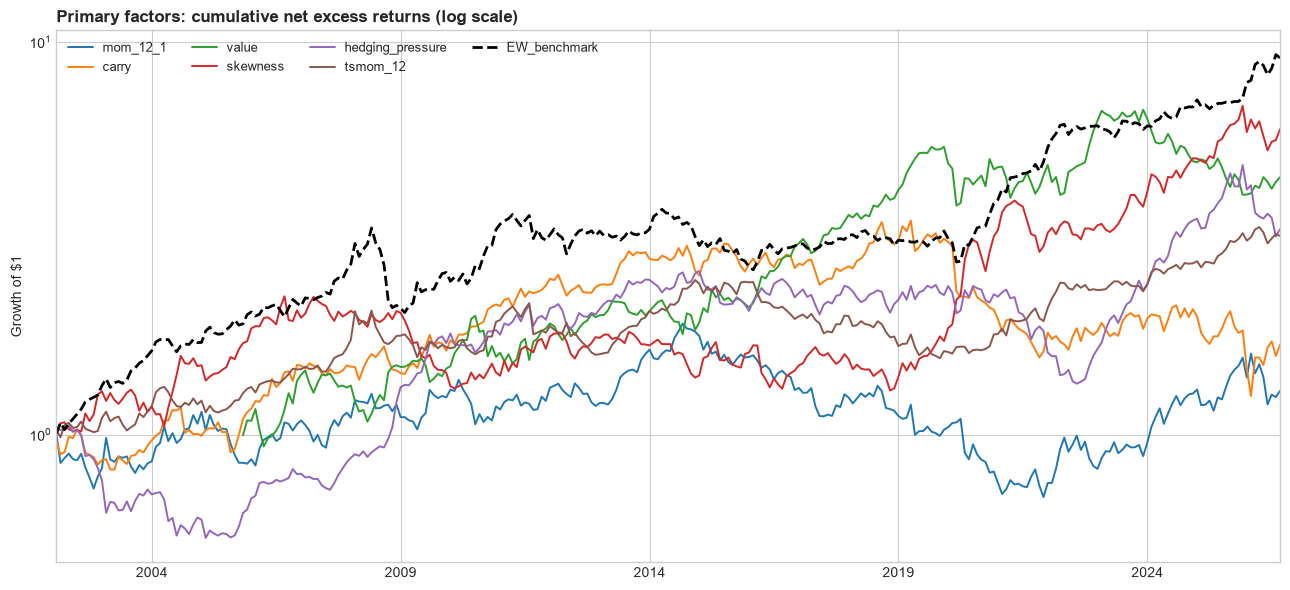

Calendar-year net returns (%)
      mom_12_1  carry  value  skewness  hedging_pressure  tsmom_12  EW_benchmark
year                                                                            
2002     -21.8  -16.1    NaN      26.6             -17.7       2.1          26.1
2003       8.0   11.7    NaN      -9.8             -11.9      12.2          26.0
2004      26.1    7.2    NaN      30.7             -15.2       4.2           8.0
2005     -20.9   13.5    8.7      15.7               4.8       9.5          17.8
2006      26.0   31.9   26.0      20.0              23.1      12.1           7.1
2007       7.0   -0.3   -3.8      -2.2               7.2      13.3          21.3
2008       4.9   -2.9   14.0       1.8              42.4       7.4         -18.7
2009       4.2   12.3   -1.9     -30.4              41.3      -6.3          21.3
2010      -5.1   31.1    7.2       0.1               7.9      15.9          28.6
2011       3.3   11.6   18.0      14.9               6.3      -6.2          -6.

In [6]:
# ============================================================
# 04 · Cell 6 — Cumulative net returns and calendar-year performance
# ============================================================
net = pd.DataFrame({name: res.net for name, res in results.items()})
net["EW_benchmark"] = benchmarks["EW_all"].loc[net.index.min():]

# 1. Cumulative returns
fig, ax = plt.subplots(figsize=(13, 6))
for name in net.columns:
    series = net[name].dropna()
    wealth = (1 + series).cumprod()
    style = {"color": "black", "lw": 2, "ls": "--"} if name == "EW_benchmark" else {"lw": 1.4}
    wealth.plot(ax=ax, logy=True, label=name, **style)

ax.set_title("Primary factors: cumulative net excess returns (log scale)", loc="left", fontweight="bold")
ax.set_ylabel("Growth of $1")
ax.set_xlabel("")
ax.legend(ncol=4, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(PATHS.figures / "04_primary_factors_cumulative.png", dpi=150)
plt.show()

# 2. Calendar-year returns (%)
annual = net.groupby(net.index.year).apply(lambda df: (1 + df).prod(min_count=1) - 1) * 100
annual.index.name = "year"
print("Calendar-year net returns (%)")
print(annual.round(1).to_string(), "\n")

# 3. Concentration: share of total return from the best 2 years
best_two = {}
for name in net.columns:
    yearly = annual[name].dropna()
    best_two[name] = {
        "positive_years_%": yearly.gt(0).mean() * 100,
        "best_year": int(yearly.idxmax()),
        "best_year_%": yearly.max(),
        "worst_year": int(yearly.idxmin()),
        "worst_year_%": yearly.min(),
        "sum_excl_best_2_%": yearly.sort_values().iloc[:-2].sum(),
    }
print("Year-level robustness")
print(pd.DataFrame(best_two).T.round(1).to_string())

In [7]:
# ============================================================
# 04 · Cell 7 — Construction robustness: weighting, sector-neutral, quintiles
# ============================================================
sector_map = UNIVERSE.sector_map

variants = {
    "base": lambda: QuantileLongShort(),
    "inverse_vol": lambda: QuantileLongShort(volatility=volatility),
    "sector_neutral": lambda: QuantileLongShort(sectors=sector_map),
    "quintile": lambda: QuantileLongShort(quantile=0.2, min_assets=10),
}

variant_results = {
    (factor, variant): backtester.run(make().weights(signals[factor]), start=BACKTEST_START)
    for factor in PRIMARY_CROSS_SECTIONAL
    for variant, make in variants.items()
}

def net_stats(res) -> dict:
    report = PerformanceReport(res.net).table().iloc[0]
    return {"sharpe": report["sharpe"], "t_stat_nw": report["t_stat_nw"],
            "ann_return_%": report["ann_return_%"]}

stats = pd.DataFrame({key: net_stats(res) for key, res in variant_results.items()}).T
stats.index.names = ["factor", "variant"]

for metric in ["sharpe", "t_stat_nw", "ann_return_%"]:
    print(f"Net {metric} by construction variant")
    print(stats[metric].unstack("variant")[list(variants)].astype(float).round(2).to_string(), "\n")

# Average net sector exposure of the base portfolios
sector_exposure = pd.DataFrame(
    {
        factor: variant_results[(factor, "base")].weights.T.groupby(pd.Series(sector_map)).sum().T.mean()
        for factor in PRIMARY_CROSS_SECTIONAL
    }
).T
print("Average net sector exposure, base portfolios (+ = net long the sector)")
print(sector_exposure.round(2).to_string())

Net sharpe by construction variant
variant           base  inverse_vol  sector_neutral  quintile
factor                                                       
carry             0.21         0.27            0.35      0.18
hedging_pressure  0.38         0.50            0.44      0.27
mom_12_1          0.15         0.26           -0.06     -0.01
skewness          0.50         0.37            0.45      0.60
value             0.48         0.23            0.69      0.48 

Net t_stat_nw by construction variant
variant           base  inverse_vol  sector_neutral  quintile
factor                                                       
carry             1.20         1.63            1.79      0.92
hedging_pressure  1.61         2.17            2.11      1.19
mom_12_1          0.83         1.43           -0.26     -0.05
skewness          2.31         1.63            2.19      2.70
value             2.29         1.04            3.28      2.14 

Net ann_return_% by construction variant
variant       

In [8]:
# ============================================================
# 04 · Cell 8 — Signal-definition robustness
# ============================================================
ENERGY = ["CL", "HO", "NG", "RB"]
time_series = VolScaledTimeSeries(volatility)

robustness_runs = {}

# 1. Cross-sectional alternatives (base construction)
for name in ["mom_12_1", "mom_12_0", "hedging_pressure", "hp_demeaned", "hp_speculator"]:
    robustness_runs[("cross_sectional", name)] = results.get(name) or backtester.run(
        QuantileLongShort().weights(signals[name]), start=BACKTEST_START
    )

# 2. Energy-only time-series versions (same 4 contracts, same construction)
energy_signals = {
    "carry (roll yield)": signals["carry"][ENERGY],
    "carry_eia_adj": signals["carry_eia_adj"][ENERGY],
    "carry_eia_raw": signals["carry_eia_raw"][ENERGY],
    "basis_momentum": signals["basis_momentum"][ENERGY],
    "tsmom_12": signals["tsmom_12"][ENERGY],
}
for name, signal in energy_signals.items():
    robustness_runs[("energy_time_series", name)] = backtester.run(
        time_series.weights(signal.loc[:"2024-03-31"]), start=BACKTEST_START
    )

columns = ["start", "months", "ann_return_%", "ann_vol_%", "sharpe", "t_stat_nw", "max_dd_%", "hit_rate_%"]
for group in ["cross_sectional", "energy_time_series"]:
    frame = pd.DataFrame({name: res.net for (g, name), res in robustness_runs.items() if g == group})
    print(f"Net performance: {group.replace('_', ' ')}")
    print(PerformanceReport(frame).table()[columns].to_string(float_format=lambda x: f"{x:.2f}"), "\n")

# Correlation of monthly net returns within each comparison
pairs = [("mom_12_1", "mom_12_0"), ("hedging_pressure", "hp_demeaned"), ("hedging_pressure", "hp_speculator")]
print("Correlation of monthly net factor returns")
for a, b in pairs:
    ra, rb = robustness_runs[("cross_sectional", a)].net, robustness_runs[("cross_sectional", b)].net
    print(f"  {a:<17} vs {b:<14}: {ra.corr(rb):.2f}")

Net performance: cross sectional
                    start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_% hit_rate_%
mom_12_1          2002-02    296         2.83     18.90   0.15      0.83   -63.83      51.69
mom_12_0          2002-02    296        -0.54     18.95  -0.03     -0.15   -76.56      50.00
hedging_pressure  2002-02    296         6.30     16.69   0.38      1.61   -48.34      58.11
hp_demeaned       2002-02    296         4.97     14.59   0.34      1.59   -40.03      56.42
hp_speculator     2002-02    296         2.38     16.00   0.15      0.61   -72.43      57.09 

Net performance: energy time series
                      start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_% hit_rate_%
carry (roll yield)  2002-02    267       -10.75     24.39  -0.44     -1.85   -96.15      44.57
carry_eia_adj       2002-02    267         0.02     23.81   0.00      0.00   -76.37      52.06
carry_eia_raw       2002-02    267         3.23     24.79   0.13      0.59   -79.53   

In [9]:
# ============================================================
# 04 · Cell 9 — Transaction cost sensitivity (rebalancing + roll costs)
# ============================================================
from commodity_factors.contracts import CONTRACT_SPECS

COST_LEVELS_BPS = [0, 5, 10, 20]
rolls_per_month = pd.Series({s: len(spec.month_codes) / 12 for s, spec in CONTRACT_SPECS.items()})


def roll_turnover(weights: pd.DataFrame) -> pd.Series:
    """Estimated monthly turnover from rolling held contracts into the next expiry."""
    held = weights.abs().reindex(columns=rolls_per_month.index).fillna(0.0)
    return (held * rolls_per_month).sum(axis=1).reindex(monthly_returns.index).shift(1)


cost_rows = {}
for name, res in results.items():
    rebalance = res.turnover
    rolling = roll_turnover(res.weights).reindex(res.gross.index)
    total_turnover = rebalance + rolling

    row = {
        "rebalance_turnover_pa": rebalance.mean() * 12,
        "roll_turnover_pa": rolling.mean() * 12,
    }
    for bps in COST_LEVELS_BPS:
        net = res.gross - total_turnover * bps / 10_000
        row[f"sharpe_{bps}bps"] = net.mean() / net.std() * np.sqrt(12)
    row["breakeven_bps"] = res.gross.mean() / total_turnover.mean() * 10_000
    cost_rows[name] = row

cost_table = pd.DataFrame(cost_rows).T
print("Net Sharpe by cost per unit of turnover (rebalancing + rolling)")
print(cost_table.round(2).to_string())

Net Sharpe by cost per unit of turnover (rebalancing + rolling)
                  rebalance_turnover_pa  roll_turnover_pa  sharpe_0bps  sharpe_5bps  sharpe_10bps  sharpe_20bps  breakeven_bps
mom_12_1                           9.19             14.04         0.17         0.11          0.05         -0.07          14.16
carry                              5.67             14.48         0.23         0.17          0.11         -0.00          19.99
value                              6.53             13.76         0.50         0.44          0.39          0.28          45.78
skewness                           7.24             14.08         0.52         0.46          0.40          0.28          43.04
hedging_pressure                   2.20             13.41         0.38         0.34          0.29          0.20          41.04
tsmom_12                           6.37             10.99         0.47         0.40          0.33          0.19          33.50


In [10]:
# ============================================================
# 04 · Cell 10 — Long-only factor tilts vs the equal-weight benchmark
# ============================================================
from commodity_factors.analytics import newey_west_tstat

ew_benchmark = benchmarks["EW_all"]
long_only_rows, long_only_excess = {}, {}

for name in PRIMARY_CROSS_SECTIONAL:
    res = results[name]
    long_w = res.weights.clip(lower=0)
    long_w = long_w.div(long_w.sum(axis=1), axis=0)
    turnover = (
        long_w.diff().abs().sum(axis=1)
        .reindex(monthly_returns.index).shift(1)
        .reindex(res.long_leg.index).fillna(0.0)
    )
    long_net = res.long_leg - turnover * COST_PER_TURNOVER
    bench = ew_benchmark.reindex(long_net.index)
    excess = long_net - bench
    long_only_excess[name] = excess

    long_only_rows[name] = {
        "start": long_net.index[0].strftime("%Y-%m"),
        "tilt_ann_ret_%": long_net.mean() * 12 * 100,
        "ew_ann_ret_%": bench.mean() * 12 * 100,
        "excess_ann_%": excess.mean() * 12 * 100,
        "tracking_error_%": excess.std() * np.sqrt(12) * 100,
        "info_ratio": excess.mean() / excess.std() * np.sqrt(12),
        "t_stat_nw": newey_west_tstat(excess),
        "beta_to_ew": long_net.cov(bench) / bench.var(),
        "pct_months_beat_%": excess.gt(0).mean() * 100,
        "annual_turnover": turnover.mean() * 12,
    }

long_only_table = pd.DataFrame(long_only_rows).T
print("Long-only top-tercile tilts vs equal-weight benchmark (net of 5 bps rebalancing)")
print(long_only_table.to_string(float_format=lambda x: f"{x:.2f}"))

pd.DataFrame(long_only_excess).to_parquet(PATHS.processed / "long_only_excess.parquet")
print("\nSaved long_only_excess.parquet")

Long-only top-tercile tilts vs equal-weight benchmark (net of 5 bps rebalancing)
                    start tilt_ann_ret_% ew_ann_ret_% excess_ann_% tracking_error_% info_ratio t_stat_nw beta_to_ew pct_months_beat_% annual_turnover
mom_12_1          2002-02          11.47         9.88         1.59            10.20       0.16      0.84       1.01             48.65            4.39
carry             2002-02          12.24         9.88         2.36            10.02       0.24      1.29       1.07             55.07            2.54
value             2005-11          12.04         8.48         3.56            10.68       0.33      1.56       0.96             53.78            3.13
skewness          2002-02          13.41         9.88         3.53             9.82       0.36      1.70       1.02             49.66            3.44
hedging_pressure  2002-02          12.73         9.88         2.84             9.60       0.30      1.33       0.89             57.09            0.97

Saved long_only_ex

In [11]:
# ============================================================
# 04 · Cell 11 — Headline net returns (rebalancing + roll costs) and save
# ============================================================
HEADLINE_COST_BPS = 5

headline_net = {}
for name, res in results.items():
    total_turnover = res.turnover + roll_turnover(res.weights).reindex(res.gross.index)
    headline_net[name] = res.gross - total_turnover * HEADLINE_COST_BPS / 10_000
headline_net = pd.DataFrame(headline_net)

# 1. Headline table
columns = ["start", "months", "ann_return_%", "ann_vol_%", "sharpe", "t_stat_nw", "max_dd_%",
           "skew", "hit_rate_%"]
headline = headline_net.copy()
headline["EW_benchmark"] = benchmarks["EW_all"].loc[headline.index.min():]
print(f"HEADLINE: primary factors, net of {HEADLINE_COST_BPS} bps on rebalancing + roll turnover")
print(PerformanceReport(headline).table()[columns].to_string(float_format=lambda x: f"{x:.2f}"), "\n")

# 2. Save everything notebook 05 needs
outputs = {
    "factor_returns_headline": headline_net,
    "factor_returns_gross": pd.DataFrame({n: r.gross for n, r in results.items()}),
    "factor_long_legs": pd.DataFrame({n: r.long_leg for n, r in results.items()}),
    "factor_short_legs": pd.DataFrame({n: r.short_leg for n, r in results.items()}),
    "variant_returns_net": pd.DataFrame(
        {f"{f}__{v}": r.net for (f, v), r in variant_results.items()}
    ),
    "robustness_returns_net": pd.DataFrame(
        {f"{g}__{n}": r.net for (g, n), r in robustness_runs.items()}
    ),
}
for file_name, frame in outputs.items():
    frame.to_parquet(PATHS.processed / f"{file_name}.parquet")

pd.concat({n: r.weights for n, r in results.items()}, axis=1, names=["factor", "symbol"]).to_parquet(
    PATHS.processed / "factor_weights.parquet"
)
print("Saved to data/processed:")
for file_name in list(outputs) + ["factor_weights"]:
    print(f"  {file_name}.parquet")

HEADLINE: primary factors, net of 5 bps on rebalancing + roll turnover
                    start months ann_return_% ann_vol_% sharpe t_stat_nw max_dd_%  skew hit_rate_%
mom_12_1          2002-02    296         2.13     18.90   0.11      0.62   -65.66 -0.11      51.01
carry             2002-02    296         3.02     17.82   0.17      0.97   -66.01 -0.35      52.36
value             2005-11    251         8.27     18.62   0.44      2.12   -39.99 -0.01      59.36
skewness          2002-02    296         8.11     17.67   0.46      2.13   -47.12  0.31      53.38
hedging_pressure  2002-02    296         5.63     16.69   0.34      1.44   -51.03 -0.47      57.77
tsmom_12          2002-02    296         4.95     12.43   0.40      2.03   -38.53  0.08      56.76
EW_benchmark      2002-02    296         9.88     13.38   0.74      3.33   -39.10 -0.35      62.50 

Saved to data/processed:
  factor_returns_headline.parquet
  factor_returns_gross.parquet
  factor_long_legs.parquet
  factor_short_leg

In [13]:
# ============================================================
# 04 · Cell 12 — Sector and contract attribution
# ============================================================
def contributions(res) -> pd.DataFrame:
    """Monthly gross return contribution per contract: weight at t-1 x return at t."""
    held = res.weights.reindex(columns=monthly_returns.columns).fillna(0.0)
    held = held.reindex(monthly_returns.index).shift(1).reindex(res.gross.index)
    return held * monthly_returns.reindex(res.gross.index).fillna(0.0)


contrib = {name: contributions(res) for name, res in results.items()}

# Check: contributions add up to the gross return
max_gap = max((contrib[n].sum(axis=1) - results[n].gross).abs().max() for n in results)
print(f"Attribution check (max gap vs gross return): {max_gap:.2e}\n")

# 1. Sector attribution (annualised %)
sector_of = pd.Series(UNIVERSE.sector_map)
sector_attr = pd.DataFrame(
    {name: c.T.groupby(sector_of).sum().T.mean() * 12 * 100 for name, c in contrib.items()}
).T
sector_attr["total"] = sector_attr.sum(axis=1)
print("Gross return contribution by sector (% per year)")
print(sector_attr.round(2).to_string(), "\n")

# 2. Top and bottom contracts per factor (% per year)
print("Largest contributors by contract (% per year)")
for name, c in contrib.items():
    by_contract = (c.mean() * 12 * 100).sort_values()
    top = ", ".join(f"{s} {v:+.2f}" for s, v in by_contract.tail(3)[::-1].items())
    bottom = ", ".join(f"{s} {v:+.2f}" for s, v in by_contract.head(3).items())
    print(f"  {name:<17} top: {top:<36} bottom: {bottom}")
print()

# 3. Concentration: share of total return from the top 3 contracts
concentration = {}
for name, c in contrib.items():
    by_contract = c.sum()
    total = by_contract.sum()
    concentration[name] = {
        "total_gross_%": total * 100,
        "top3_share_%": by_contract.nlargest(3).sum() / total * 100 if total > 0 else np.nan,
        "positive_contracts": int((by_contract > 0).sum()),
    }
print("Concentration of cumulative gross return")
print(pd.DataFrame(concentration).T.round(1).to_string(), "\n")

# 4. Episodes flagged in Cell 6
episodes = {
    "skewness 2020": ("skewness", "2020", "2020"),
    "hedging_pressure 2023-2025": ("hedging_pressure", "2023", "2025"),
}
for label, (name, start, end) in episodes.items():
    window = contrib[name].loc[start:end].sum() * 100
    print(f"{label}: total {window.sum():+.1f}% (sum of monthly contributions)")
    print(f"  top 5   : {window.nlargest(5).round(1).to_dict()}")
    print(f"  bottom 5: {window.nsmallest(5).round(1).to_dict()}\n")

Attribution check (max gap vs gross return): 0.00e+00

Gross return contribution by sector (% per year)
                  Energy  Grains  Livestock  Metals  Softs  total
mom_12_1           -2.78    2.10      -0.76    2.57   2.16   3.29
carry              -1.98    4.67       0.31    1.21  -0.18   4.03
value               5.01    3.19      -0.43   -2.95   4.46   9.29
skewness            5.66   -1.63       0.29    2.63   2.23   9.17
hedging_pressure   -1.72    2.69      -1.30    4.12   2.62   6.41
tsmom_12            0.92    2.22       1.43    1.40  -0.16   5.82 

Largest contributors by contract (% per year)
  mom_12_1          top: CC +1.16, OJ +1.08, SI +1.05         bottom: RB -1.23, HE -1.12, BZ -0.65
  carry             top: ZM +2.18, ZS +1.36, RB +1.22         bottom: NG -1.45, KC -0.82, HO -0.71
  value             top: RB +2.13, KC +1.41, OJ +1.32         bottom: SI -1.11, GC -0.97, HG -0.86
  skewness          top: RB +2.13, HO +1.77, CL +1.60         bottom: KE -0.85, ZM -0.72,

Stability and drawdowns (net of 5 bps incl. rolls)
                  pct_3y_windows_positive  worst_3y_sharpe  best_3y_sharpe  latest_3y_sharpe  max_drawdown_%  longest_underwater_months  current_drawdown_%
mom_12_1                            63.60            -1.45            1.30              0.56          -65.66                      144.0              -37.99
carry                               71.26            -1.05            1.50             -0.11          -66.01                       89.0              -54.25
value                               90.28            -1.07            2.29             -0.72          -39.99                       43.0              -33.78
skewness                            67.05            -1.34            1.64              0.71          -47.12                      163.0              -13.33
hedging_pressure                    70.11            -1.01            3.06              0.73          -51.03                      110.0              -31.77
tsmom_12     

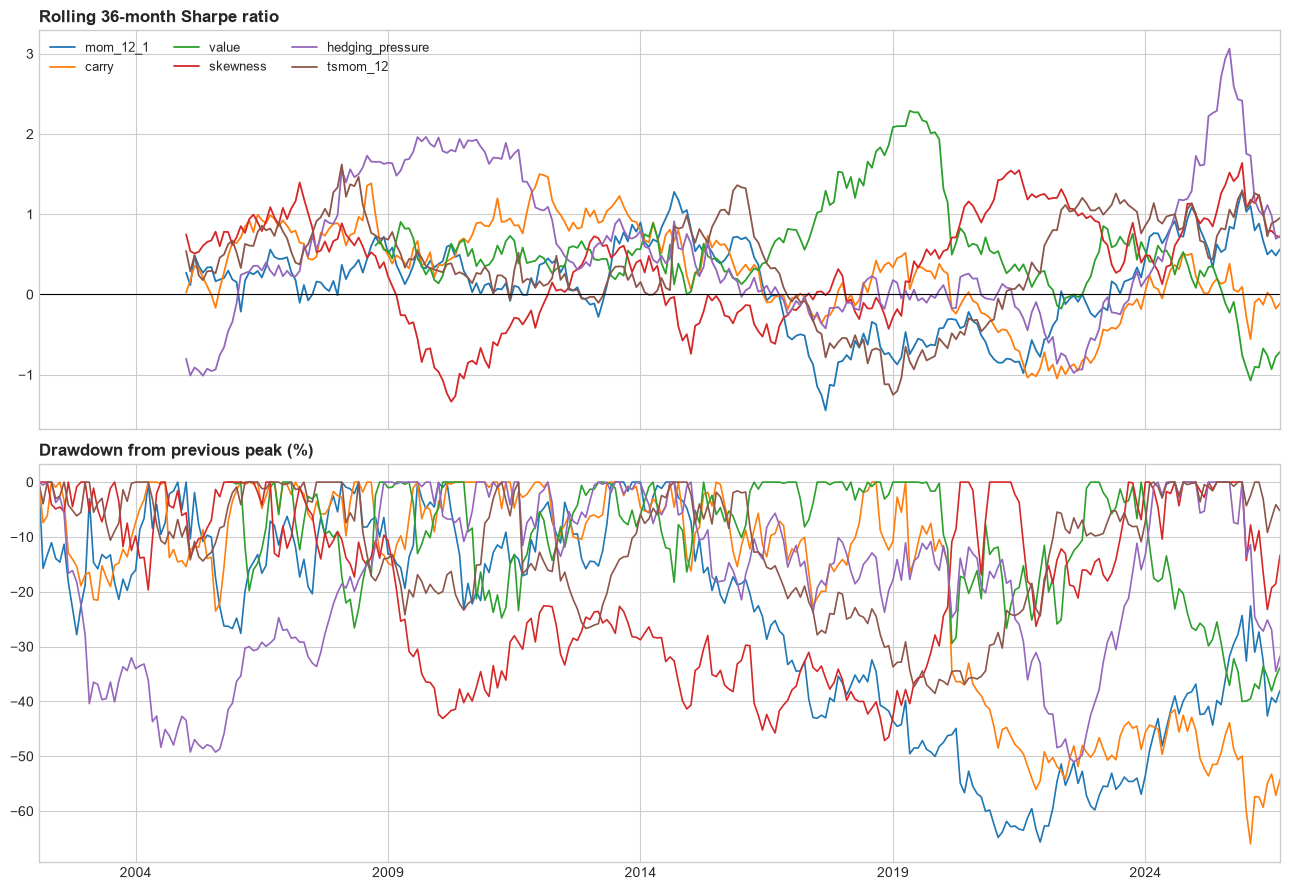

In [14]:
# ============================================================
# 04 · Cell 13 — Rolling 3-year Sharpe and drawdowns
# ============================================================
WINDOW = 36
net = headline_net.copy()


def longest_run(mask: pd.Series) -> int:
    """Longest run of consecutive True values."""
    runs = mask.ne(mask.shift()).cumsum()
    lengths = mask.groupby(runs).sum()
    return int(lengths.max()) if len(lengths) else 0


rolling_sharpe = (
    net.rolling(WINDOW, min_periods=WINDOW).mean()
    / net.rolling(WINDOW, min_periods=WINDOW).std()
    * np.sqrt(12)
)

drawdowns, stability = {}, {}
for name in net.columns:
    series = net[name].dropna()
    wealth = (1 + series).cumprod()
    dd = wealth / wealth.cummax() - 1
    drawdowns[name] = dd
    rs = rolling_sharpe[name].dropna()
    stability[name] = {
        "pct_3y_windows_positive": rs.gt(0).mean() * 100,
        "worst_3y_sharpe": rs.min(),
        "best_3y_sharpe": rs.max(),
        "latest_3y_sharpe": rs.iloc[-1],
        "max_drawdown_%": dd.min() * 100,
        "longest_underwater_months": longest_run(dd < 0),
        "current_drawdown_%": dd.iloc[-1] * 100,
    }
drawdowns = pd.DataFrame(drawdowns)

print("Stability and drawdowns (net of 5 bps incl. rolls)")
print(pd.DataFrame(stability).T.round(2).to_string())

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
rolling_sharpe.plot(ax=axes[0], lw=1.3)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title("Rolling 36-month Sharpe ratio", loc="left", fontweight="bold")
axes[0].legend(ncol=3, fontsize=9, loc="upper left")

(drawdowns * 100).plot(ax=axes[1], lw=1.2, legend=False)
axes[1].set_title("Drawdown from previous peak (%)", loc="left", fontweight="bold")
axes[1].set_xlabel("")

fig.tight_layout()
fig.savefig(PATHS.figures / "04_rolling_sharpe_drawdowns.png", dpi=150)
plt.show()

In [15]:
# ============================================================
# 04 · Cell 14 — Crisis and episode event study
# ============================================================
EVENTS = {
    "GFC crash (2008-07 to 2009-02)": ("2008-07", "2009-02"),
    "Post-GFC reflation (2009-03 to 2011-04)": ("2009-03", "2011-04"),
    "Oil collapse (2014-07 to 2016-01)": ("2014-07", "2016-01"),
    "COVID crash (2020-01 to 2020-04)": ("2020-01", "2020-04"),
    "Reopening rally (2020-05 to 2022-02)": ("2020-05", "2022-02"),
    "Ukraine shock (2022-03 to 2022-06)": ("2022-03", "2022-06"),
    "Post-shock unwind (2022-07 to 2022-12)": ("2022-07", "2022-12"),
}

event_frame = headline_net.copy()
event_frame["EW_benchmark"] = benchmarks["EW_all"].reindex(event_frame.index)

event_table = pd.DataFrame(
    {
        label: ((1 + event_frame.loc[start:end]).prod(min_count=1) - 1) * 100
        for label, (start, end) in EVENTS.items()
    }
).T
print("Cumulative net return in each episode (%)")
print(event_table.round(1).to_string(), "\n")

# Which factors hedge commodity sell-offs? Correlation with the benchmark in its worst months
bench = event_frame["EW_benchmark"]
worst = bench.le(bench.quantile(0.10))
best = bench.ge(bench.quantile(0.90))
tail_table = pd.DataFrame(
    {
        "avg_in_worst_10%_bench_months": event_frame.loc[worst].mean() * 100,
        "avg_in_best_10%_bench_months": event_frame.loc[best].mean() * 100,
        "avg_all_months": event_frame.mean() * 100,
        "corr_with_bench": event_frame.corr()["EW_benchmark"],
    }
)
print("Behaviour in the benchmark's worst and best 10% of months (average monthly %)")
print(tail_table.round(2).to_string())

Cumulative net return in each episode (%)
                                         mom_12_1  carry  value  skewness  hedging_pressure  tsmom_12  EW_benchmark
GFC crash (2008-07 to 2009-02)              -13.2  -11.5   31.0      -4.2              47.9     -13.2         -39.1
Post-GFC reflation (2009-03 to 2011-04)       8.6   46.0    0.4     -23.2              42.9      16.5          77.6
Oil collapse (2014-07 to 2016-01)            -4.4   -3.2    4.3      -5.8             -12.9      12.6         -26.9
COVID crash (2020-01 to 2020-04)              6.4  -29.0  -28.2      30.4              -8.9       2.4         -16.3
Reopening rally (2020-05 to 2022-02)        -32.3  -23.2   11.6      46.6             -24.5      31.5         104.7
Ukraine shock (2022-03 to 2022-06)           19.9   -6.3    5.9       2.6              -7.9       6.0           2.6
Post-shock unwind (2022-07 to 2022-12)       -8.4    8.7   26.7      -4.4               8.2      -0.7           5.0 

Behaviour in the benchmark's

In [16]:
%%writefile src/commodity_factors/data/macro.py
"""Macro and market series for regime analysis: FRED (no API key) and Yahoo indices."""

from __future__ import annotations

import io
from pathlib import Path

import pandas as pd
import requests
import yfinance as yf

from commodity_factors.data.base import CachedDataSource


class FREDSource(CachedDataSource):
    """FRED series via the public CSV endpoint; one column per series label.

    Missing observations (published as '.') become NaN. Dates are the
    observation dates as published (monthly series are dated the 1st).
    """

    name = "fred_macro"
    URL = "https://fred.stlouisfed.org/graph/fredgraph.csv"

    def __init__(
        self,
        series: dict[str, str],
        cache_dir: Path,
        start: str = "1995-01-01",
        timeout: float = 60.0,
    ) -> None:
        super().__init__(cache_dir)
        self._series = series
        self._start = start
        self._timeout = timeout

    def fetch(self) -> pd.DataFrame:
        frames = {label: self._fetch_series(series_id) for label, series_id in self._series.items()}
        return pd.concat(frames, axis=1, sort=True)

    def _fetch_series(self, series_id: str) -> pd.Series:
        response = requests.get(
            self.URL, params={"id": series_id, "cosd": self._start}, timeout=self._timeout
        )
        response.raise_for_status()
        frame = pd.read_csv(io.StringIO(response.text))
        dates = pd.to_datetime(frame.iloc[:, 0])
        values = pd.to_numeric(frame.iloc[:, 1], errors="coerce")
        return pd.Series(values.to_numpy(), index=pd.DatetimeIndex(dates), name=series_id)


class YahooSeriesSource(CachedDataSource):
    """Daily closing levels for a set of Yahoo index tickers (label -> ticker)."""

    name = "yahoo_indices"

    def __init__(
        self,
        tickers: dict[str, str],
        cache_dir: Path,
        start: str = "1995-01-01",
    ) -> None:
        super().__init__(cache_dir)
        self._tickers = tickers
        self._start = start

    def fetch(self) -> pd.DataFrame:
        end = pd.Timestamp.today().strftime("%Y-%m-%d")
        raw = yf.download(
            list(self._tickers.values()),
            start=self._start,
            end=end,
            auto_adjust=False,
            progress=False,
        )
        closes = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw[["Close"]]
        closes.columns = [str(c) for c in closes.columns]
        rename = {ticker: label for label, ticker in self._tickers.items()}
        if len(self._tickers) == 1 and "Close" in closes.columns:
            closes.columns = list(self._tickers.values())
        return closes.rename(columns=rename)[list(self._tickers)]

Writing src/commodity_factors/data/macro.py


In [17]:
# ============================================================
# 04 · Cell 16 — Macro data and regime indicators
# ============================================================
from commodity_factors.data.macro import FREDSource, YahooSeriesSource

fred = FREDSource({"cpi": "CPIAUCSL", "vix": "VIXCLS", "recession": "USREC"}, cache_dir=PATHS.raw)
macro = fred.load(refresh=False)
indices = YahooSeriesSource({"dxy": "DX-Y.NYB"}, cache_dir=PATHS.raw).load(refresh=False)

print("Macro data coverage")
for label, series in list(macro.items()) + list(indices.items()):
    valid = series.dropna()
    print(f"  {label:<10}: {valid.index.min():%Y-%m-%d} -> {valid.index.max():%Y-%m-%d} ({len(valid):,} obs)")
print()

month_end = lambda s: s.dropna().resample("ME").last()
bench = benchmarks["EW_all"]

trailing_12m = (1 + bench).rolling(12).apply(np.prod, raw=True) - 1
vol_12m = bench.rolling(12).std()
cpi_yoy = month_end(macro["cpi"]).pct_change(12, fill_method=None)
dxy_12m = month_end(indices["dxy"]).pct_change(12, fill_method=None)
vix_level = month_end(macro["vix"])

regimes = pd.DataFrame(
    {
        "commodity_rising": trailing_12m.shift(1) > 0,
        "commodity_high_vol": (vol_12m > vol_12m.expanding(min_periods=36).median()).shift(1),
        "inflation_high": cpi_yoy.shift(2) > 0.03,
        "dollar_strengthening": dxy_12m.shift(1) > 0,
        "equity_stress_vix25": vix_level.shift(1) > 25,
        "recession_ex_post": month_end(macro["recession"]) > 0,
    }
).reindex(headline_net.index)

valid_regimes = regimes.notna() & regimes.astype("boolean").notna()
print("Share of backtest months in each state (True)")
summary = pd.DataFrame(
    {
        "months_true": regimes.astype("boolean").sum(),
        "months_false": (~regimes.astype("boolean")).sum(),
        "pct_true": regimes.astype("boolean").mean() * 100,
    }
)
print(summary.round(1).to_string(), "\n")

print("Overlap between regimes (correlation of indicators)")
print(regimes.astype(float).corr().round(2).to_string())

Macro data coverage
  cpi       : 1995-01-01 -> 2026-09-01 (380 obs)
  vix       : 1995-01-03 -> 2026-10-15 (8,032 obs)
  recession : 1995-01-01 -> 2026-09-01 (381 obs)
  dxy       : 1995-01-02 -> 2026-10-16 (8,070 obs)

Share of backtest months in each state (True)
                      months_true  months_false  pct_true
commodity_rising              221            75      74.7
commodity_high_vol            152           144      51.4
inflation_high                 90           206      30.4
dollar_strengthening          141           155      47.6
equity_stress_vix25            56           240      18.9
recession_ex_post              20           276       6.8 

Overlap between regimes (correlation of indicators)
                      commodity_rising  commodity_high_vol  inflation_high  dollar_strengthening  equity_stress_vix25  recession_ex_post
commodity_rising                  1.00               -0.07            0.23                 -0.46                -0.12              -0.15

commodity_rising: annualised net return (%) | TRUE = rising, FALSE = falling
                  ret_true_%  ret_false_%  diff_%  t_diff  sharpe_true  sharpe_false
mom_12_1                4.92        -6.09   11.01    1.25         0.26         -0.32
carry                   3.60         1.33    2.27    0.27         0.20          0.07
value                   6.66        12.44   -5.78   -0.65         0.35          0.69
skewness                6.06        14.15   -8.09   -0.91         0.36          0.71
hedging_pressure        1.79        16.92  -15.13   -1.95         0.11          1.01
tsmom_12                7.66        -3.05   10.71    1.85         0.62         -0.24
EW_benchmark           10.70         7.47    3.23    0.52         0.80          0.55 

commodity_high_vol: annualised net return (%) | TRUE = high vol, FALSE = low vol
                  ret_true_%  ret_false_%  diff_%  t_diff  sharpe_true  sharpe_false
mom_12_1               -1.33         5.78   -7.12   -0.93        -0.07     

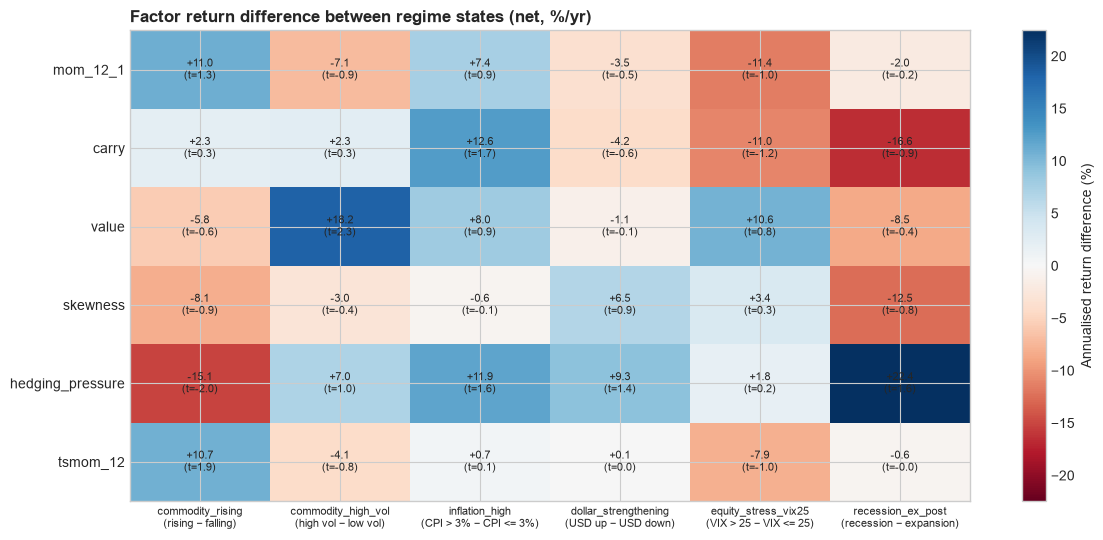

In [18]:
# ============================================================
# 04 · Cell 17 — Factor performance by regime
# ============================================================
regime_frame = headline_net.copy()
regime_frame["EW_benchmark"] = benchmarks["EW_all"].reindex(regime_frame.index)

REGIME_LABELS = {
    "commodity_rising": ("rising", "falling"),
    "commodity_high_vol": ("high vol", "low vol"),
    "inflation_high": ("CPI > 3%", "CPI <= 3%"),
    "dollar_strengthening": ("USD up", "USD down"),
    "equity_stress_vix25": ("VIX > 25", "VIX <= 25"),
    "recession_ex_post": ("recession", "expansion"),
}


def regime_split(returns: pd.Series, state: pd.Series) -> dict:
    """Annualised return in each state and a Welch t-stat for the difference."""
    data = pd.concat([returns, state.astype("boolean")], axis=1, keys=["r", "s"]).dropna()
    on, off = data.loc[data["s"], "r"], data.loc[~data["s"], "r"]
    diff = on.mean() - off.mean()
    se = np.sqrt(on.var() / len(on) + off.var() / len(off))
    return {
        "ret_true_%": on.mean() * 1200,
        "ret_false_%": off.mean() * 1200,
        "diff_%": diff * 1200,
        "t_diff": diff / se,
        "sharpe_true": on.mean() / on.std() * np.sqrt(12),
        "sharpe_false": off.mean() / off.std() * np.sqrt(12),
    }


diff_grid, t_grid = {}, {}
for regime, (true_label, false_label) in REGIME_LABELS.items():
    table = pd.DataFrame(
        {name: regime_split(regime_frame[name], regimes[regime]) for name in regime_frame.columns}
    ).T
    diff_grid[regime], t_grid[regime] = table["diff_%"], table["t_diff"]
    print(f"{regime}: annualised net return (%) | TRUE = {true_label}, FALSE = {false_label}")
    print(table.round(2).to_string(), "\n")

# Heatmap: return difference (TRUE - FALSE), annotated with t-stats
diff_grid = pd.DataFrame(diff_grid).drop(index="EW_benchmark")
t_grid = pd.DataFrame(t_grid).drop(index="EW_benchmark")

fig, ax = plt.subplots(figsize=(12, 5.5))
limit = np.nanmax(np.abs(diff_grid.to_numpy()))
image = ax.imshow(diff_grid.to_numpy(), cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(diff_grid.shape[1]))
ax.set_xticklabels([f"{r}\n({REGIME_LABELS[r][0]} − {REGIME_LABELS[r][1]})" for r in diff_grid.columns],
                   fontsize=8)
ax.set_yticks(range(diff_grid.shape[0]))
ax.set_yticklabels(diff_grid.index)
for i in range(diff_grid.shape[0]):
    for j in range(diff_grid.shape[1]):
        ax.text(j, i, f"{diff_grid.iat[i, j]:+.1f}\n(t={t_grid.iat[i, j]:.1f})",
                ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Annualised return difference (%)")
ax.set_title("Factor return difference between regime states (net, %/yr)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(PATHS.figures / "04_regime_heatmap.png", dpi=150)
plt.show()

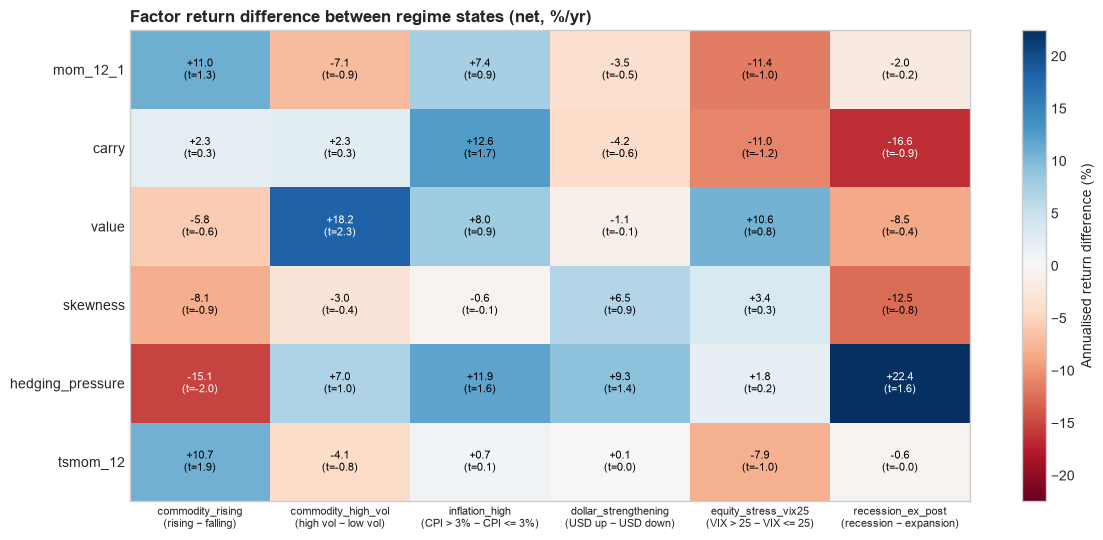

Saved 10 tables to reports\tables:
  04_headline_performance.csv
  04_construction_variants.csv
  04_cost_sensitivity.csv
  04_long_only_tilts.csv
  04_sector_attribution.csv
  04_concentration.csv
  04_stability_drawdowns.csv
  04_event_study.csv
  04_tail_behaviour.csv
  04_regimes.csv
Saved regimes.parquet to data/processed


In [19]:
# ============================================================
# 04 · Cell 18 — Save analysis tables and redraw the regime heatmap
# ============================================================
TABLES_DIR = PATHS.root / "reports" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Regime table (all factors x regimes)
regime_rows = {}
for regime in REGIME_LABELS:
    for name in regime_frame.columns:
        regime_rows[(regime, name)] = regime_split(regime_frame[name], regimes[regime])
regime_table = pd.DataFrame(regime_rows).T
regime_table.index.names = ["regime", "factor"]

tables = {
    "04_headline_performance": PerformanceReport(headline).table(),
    "04_construction_variants": stats.unstack("variant"),
    "04_cost_sensitivity": cost_table,
    "04_long_only_tilts": long_only_table,
    "04_sector_attribution": sector_attr,
    "04_concentration": pd.DataFrame(concentration).T,
    "04_stability_drawdowns": pd.DataFrame(stability).T,
    "04_event_study": event_table,
    "04_tail_behaviour": tail_table,
    "04_regimes": regime_table,
}
for file_name, table in tables.items():
    table.to_csv(TABLES_DIR / f"{file_name}.csv")

regimes.astype(float).to_parquet(PATHS.processed / "regimes.parquet")

# 2. Redraw the heatmap: no grid, readable labels on dark cells
fig, ax = plt.subplots(figsize=(12, 5.5))
values = diff_grid.to_numpy()
image = ax.imshow(values, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
ax.grid(False)
ax.set_xticks(range(diff_grid.shape[1]))
ax.set_xticklabels([f"{r}\n({REGIME_LABELS[r][0]} − {REGIME_LABELS[r][1]})" for r in diff_grid.columns],
                   fontsize=8)
ax.set_yticks(range(diff_grid.shape[0]))
ax.set_yticklabels(diff_grid.index)
for i in range(diff_grid.shape[0]):
    for j in range(diff_grid.shape[1]):
        colour = "white" if abs(values[i, j]) > 0.6 * limit else "black"
        ax.text(j, i, f"{values[i, j]:+.1f}\n(t={t_grid.iat[i, j]:.1f})",
                ha="center", va="center", fontsize=8, color=colour)
fig.colorbar(image, ax=ax, label="Annualised return difference (%)")
ax.set_title("Factor return difference between regime states (net, %/yr)", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(PATHS.figures / "04_regime_heatmap.png", dpi=150)
plt.show()

print(f"Saved {len(tables)} tables to {TABLES_DIR.relative_to(PATHS.root)}:")
for file_name in tables:
    print(f"  {file_name}.csv")
print("Saved regimes.parquet to data/processed")